# Liver Disorder Classification Using ANFIS

## Overview
This project implements an Adaptive Neuro-Fuzzy Inference System (ANFIS) to classify liver disorders using the UCI Indian Liver Patient dataset. ANFIS combines fuzzy logic with neural network learning to model relationships between input features and classification outcomes.

The implementation uses four biochemical features: Total Bilirubin (TB), Direct Bilirubin (DB), Alkaline Phosphotase (Alkphos), and Alanine Aminotransferase (Sgpt). The dataset is preprocessed, split into training and testing sets, and normalized before training the model.

## Objectives
- Implement an ANFIS model using PyTorch.
- Handle class imbalance using a weighted binary cross-entropy loss.
- Train the model using Gaussian membership functions and learnable rule consequents.
- Evaluate performance using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.
- Visualize training loss and learned membership functions.
- Compare ANFIS with Logistic Regression to understand their relative classification performance.

## Methodology
The workflow consists of dataset loading, data inspection, preprocessing, feature selection, stratified train-test splitting, feature scaling, ANFIS model construction, model training, evaluation, and comparison with a Logistic Regression baseline.

## Evaluation
Both models are evaluated on the same test set using multiple classification metrics. The comparison helps assess their ability to identify the positive class while accounting for the imbalanced class distribution.

This project is an educational machine learning implementation and is not intended for clinical diagnosis.

Install the libraries

In [ ]:
!pip install pandas numpy scikit-learn matplotlib ucimlrepo

Load the dataset

In [ ]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=225)

X = dataset.data.features
y = dataset.data.targets

print(X.head())
print(y.head())
print(X.shape)

   Age  Gender    TB   DB  Alkphos  Sgpt  Sgot   TP  ALB  A/G Ratio
0   65  Female   0.7  0.1      187    16    18  6.8  3.3       0.90
1   62    Male  10.9  5.5      699    64   100  7.5  3.2       0.74
2   62    Male   7.3  4.1      490    60    68  7.0  3.3       0.89
3   58    Male   1.0  0.4      182    14    20  6.8  3.4       1.00
4   72    Male   3.9  2.0      195    27    59  7.3  2.4       0.40
   Selector
0         1
1         1
2         1
3         1
4         1
(583, 10)


Inspect the data

In [ ]:
print(X.info())
print(X.isnull().sum())
print(y.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Age        583 non-null    int64  
 1   Gender     583 non-null    object 
 2   TB         583 non-null    float64
 3   DB         583 non-null    float64
 4   Alkphos    583 non-null    int64  
 5   Sgpt       583 non-null    int64  
 6   Sgot       583 non-null    int64  
 7   TP         583 non-null    float64
 8   ALB        583 non-null    float64
 9   A/G Ratio  579 non-null    float64
dtypes: float64(5), int64(4), object(1)
memory usage: 45.7+ KB
None
Age          0
Gender       0
TB           0
DB           0
Alkphos      0
Sgpt         0
Sgot         0
TP           0
ALB          0
A/G Ratio    4
dtype: int64
Selector
1           416
2           167
Name: count, dtype: int64


Preprocess the dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score
)

# Select four input features
features = ['TB', 'DB', 'Alkphos', 'Sgpt']

X = X[features].copy()

# Convert target to a one-dimensional array
y = y['Selector'].astype(int).to_numpy()

# Convert missing and infinite values to NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values with the median
X = X.fillna(X.median())

# Encode Selector 1 as 0 and Selector 2 as 1
y = (y == 2).astype(int)

print("Features:", X.columns.tolist())
print("Dataset shape:", X.shape)
print("Class distribution:")
print(pd.Series(y).value_counts().sort_index())

Features: ['TB', 'DB', 'Alkphos', 'Sgpt']
Dataset shape: (583, 4)
Class distribution:
0    416
1    167
Name: count, dtype: int64


Split and normalize the data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 466
Testing samples: 117


Define the ANFIS model

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(42)

class ANFIS(nn.Module):
    def __init__(self, n_inputs=4, n_mfs=2):
        super().__init__()

        self.n_inputs = n_inputs
        self.n_mfs = n_mfs

        # Gaussian membership function parameters
        self.centers = nn.Parameter(
            torch.linspace(-0.5, 0.5, n_mfs)
            .repeat(n_inputs, 1)
        )

        self.log_sigmas = nn.Parameter(
            torch.zeros(n_inputs, n_mfs)
        )

        # One linear consequent function per rule
        n_rules = n_mfs ** n_inputs
        self.consequents = nn.Parameter(
            torch.randn(n_rules, n_inputs + 1) * 0.01
        )

        # Enumerate all combinations of membership functions
        import itertools
        rules = list(itertools.product(range(n_mfs), repeat=n_inputs))

        self.register_buffer(
            "rule_indices",
            torch.tensor(rules, dtype=torch.long)
        )

    def forward(self, x):
    # Calculate membership degrees
      sigma = torch.exp(self.log_sigmas).clamp(min=0.1)

      diff = (
          x.unsqueeze(-1) - self.centers.unsqueeze(0)
      ) / sigma.unsqueeze(0)

      memberships = torch.exp(-0.5 * diff ** 2)

      # Calculate firing strength for each rule
      batch_size = x.shape[0]
      n_rules = self.rule_indices.shape[0]

      firing = torch.ones(
          batch_size, n_rules, device=x.device
      )

      for i in range(self.n_inputs):
          rule_mfs = self.rule_indices[:, i]

          selected = memberships[:, i, :][:, rule_mfs]

          firing = firing * selected

      # Normalize firing strengths
      weights = firing / (firing.sum(dim=1, keepdim=True) + 1e-8)

      # Add a constant term to the inputs
      x_aug = torch.cat(
          [x, torch.ones(batch_size, 1, device=x.device)],
          dim=1
      )

      # Calculate each rule's output
      rule_outputs = x_aug @ self.consequents.T

      # Weighted average of rule outputs
      output = (weights * rule_outputs).sum(dim=1)

      return output

Train the model

In [ ]:
# Recreate the model
model = ANFIS(n_inputs=4, n_mfs=2).to(device)

# Give more weight to the minority class
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32
).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = optim.Adam(model.parameters(), lr=0.005)

epochs = 400
loss_history = []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    logits = model(X_train_t)
    loss = criterion(logits, y_train_t)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.4f}")

print("Positive class weight:", round(pos_weight.item(), 2))

Epoch 50/400, Loss: 0.8867
Epoch 100/400, Loss: 0.8434
Epoch 150/400, Loss: 0.8146
Epoch 200/400, Loss: 0.7975
Epoch 250/400, Loss: 0.7847
Epoch 300/400, Loss: 0.7759
Epoch 350/400, Loss: 0.7696
Epoch 400/400, Loss: 0.7580
Positive class weight: 2.5


Plot the training loss

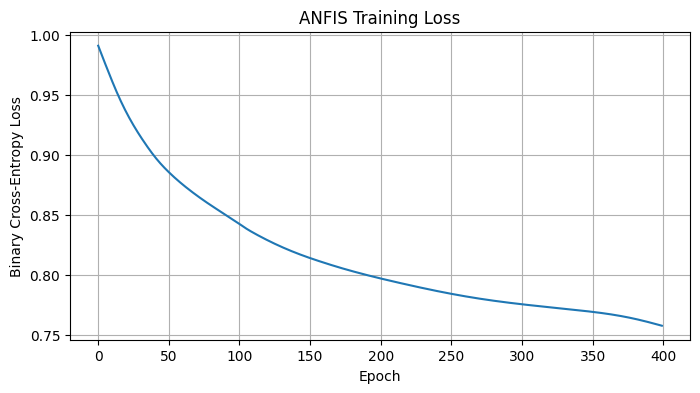

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("ANFIS Training Loss")
plt.grid(True)
plt.show()

Evaluate the model

In [ ]:
model.eval()

with torch.no_grad():
    logits = model(X_test_t)
    probabilities = torch.sigmoid(logits).cpu().numpy()

y_pred = (probabilities >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print(classification_report(y_test, y_pred, zero_division=0))

if len(np.unique(y_test)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))

Accuracy: 0.6325
Precision: 0.4308
Recall: 0.8235
F1 Score: 0.5657
              precision    recall  f1-score   support

           0       0.88      0.55      0.68        83
           1       0.43      0.82      0.57        34

    accuracy                           0.63       117
   macro avg       0.66      0.69      0.62       117
weighted avg       0.75      0.63      0.65       117

ROC-AUC: 0.6662


Display the confusion matrix

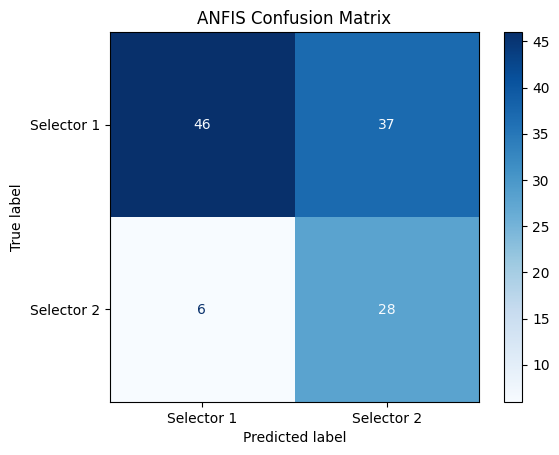

In [ ]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Selector 1", "Selector 2"]
)

disp.plot(cmap="Blues")
plt.title("ANFIS Confusion Matrix")
plt.show()

Visualize the membership functions

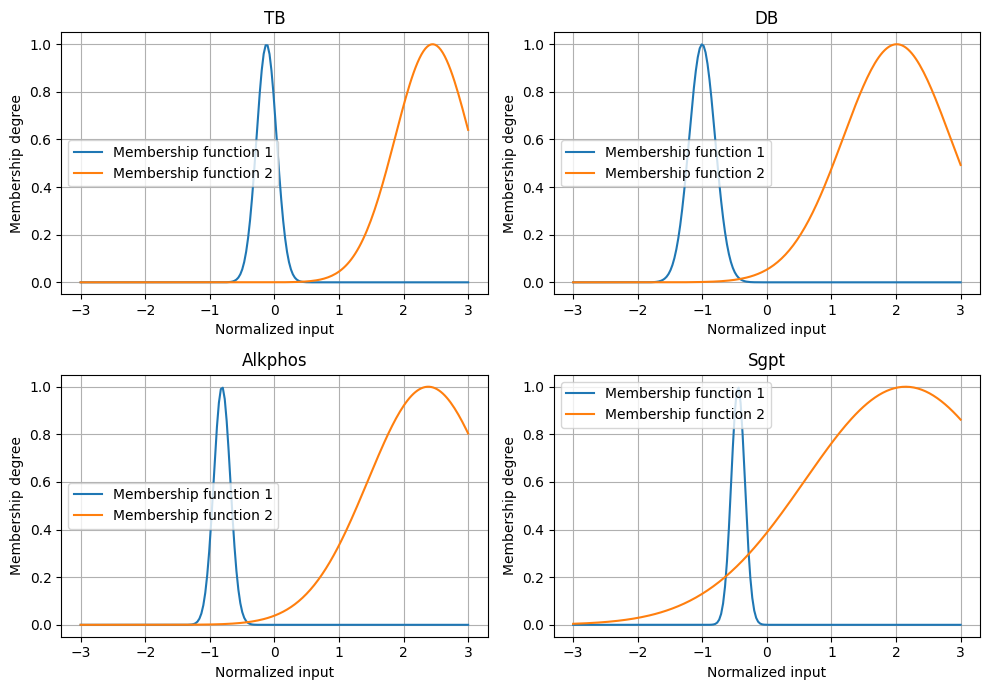

In [ ]:
centers = model.centers.detach().cpu().numpy()
sigmas = torch.exp(model.log_sigmas).detach().cpu().numpy()

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for i, ax in enumerate(axes.flat):
    x_range = np.linspace(-3, 3, 200)

    for j in range(model.n_mfs):
        mu = np.exp(
            -0.5 * ((x_range - centers[i, j]) / sigmas[i, j]) ** 2
        )

        ax.plot(x_range, mu, label=f"Membership function {j+1}")

    ax.set_title(features[i])
    ax.set_xlabel("Normalized input")
    ax.set_ylabel("Membership degree")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

Train Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

# Train Logistic Regression on the same training data
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

# Predict probabilities and classes
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]
lr_predictions = (lr_probabilities >= 0.5).astype(int)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


Compare both models

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

# Store predictions from both models
results = []

# ANFIS
results.append({
    "Model": "ANFIS",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, probabilities)
})

# Logistic Regression
results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, lr_predictions),
    "Precision": precision_score(y_test, lr_predictions, zero_division=0),
    "Recall": recall_score(y_test, lr_predictions, zero_division=0),
    "F1 Score": f1_score(y_test, lr_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, lr_probabilities)
})

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
              ANFIS    0.6325     0.4308  0.8235    0.5657   0.6662
Logistic Regression    0.6239     0.4306  0.9118    0.5849   0.7318


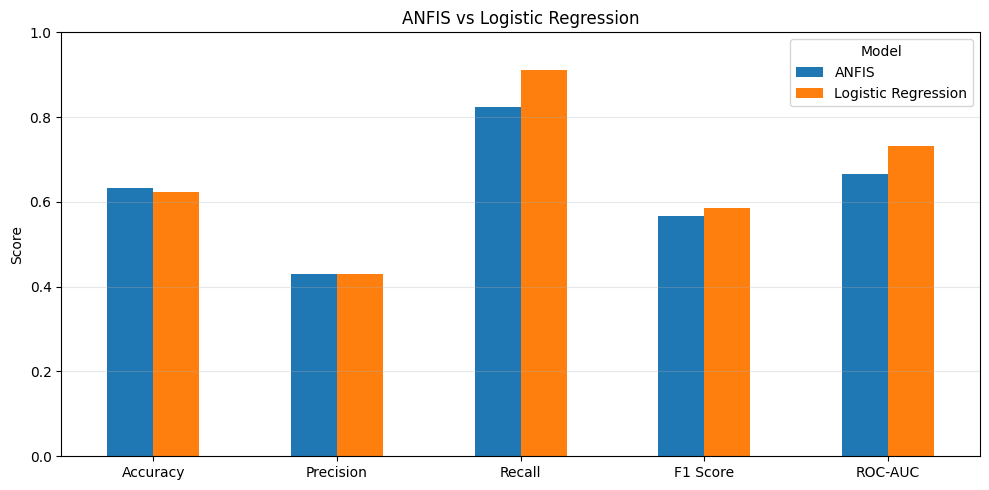

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

comparison_df.set_index("Model")[metrics].T.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("ANFIS vs Logistic Regression")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

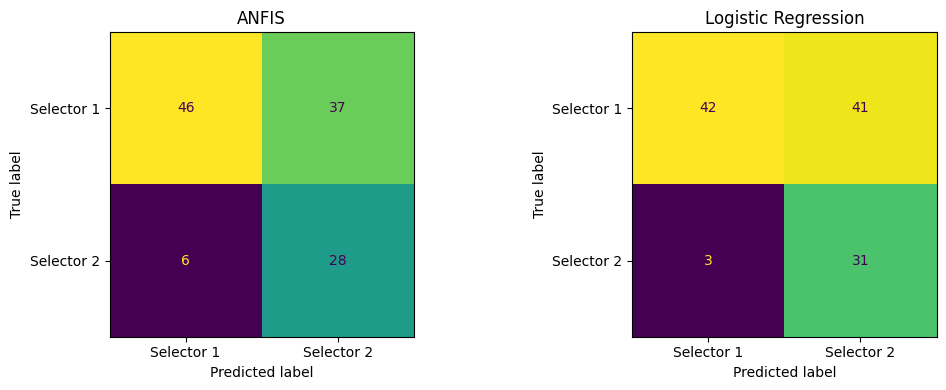

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=["Selector 1", "Selector 2"]
).plot(ax=axes[0], colorbar=False)

axes[0].set_title("ANFIS")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, lr_predictions),
    display_labels=["Selector 1", "Selector 2"]
).plot(ax=axes[1], colorbar=False)

axes[1].set_title("Logistic Regression")

plt.tight_layout()
plt.show()